In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import SimpleITK as sitk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.config import FEATURES_FILE, LNDB_DIR, PATCHES_DIR
from src.features import measure_all_patches, segment_from_centre
from src.models import CorrelationFilter, OrdinalLogisticRegression, make_size_model, size_target
from src.patches import extract_patch
from src.radiomics_features import LOG_SIGMAS_MM, SETTINGS, extract_training_radiomics, icc_2_1
from src.validation import grouped_cv_predictions, summarise

# Segmentation, features and radiomics

The functions live in `src/features.py` (handcrafted features) and `src/radiomics_features.py` (PyRadiomics and ICC).

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Segmentation and Features
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Segmenting the nodule and measuring it
  </h3>
  <p>
  The input is a 64 x 64 x 64 patch with 1 mm voxels, so distances are in mm and volumes in mm3. The only thing we know about the nodule is that its centre is at voxel (32, 32, 32).
  </p>
  <p><strong>Segmentation in five steps:</strong></p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Smooth the patch lightly (sigma 0.7 mm) to reduce noise.</li>
    <li style="margin-bottom: 8px;">Threshold halfway between the HU at the centre and the HU of the surrounding lung, which adapts to solid nodules (about 0 HU) and to ground glass ones (about -500 HU).</li>
    <li style="margin-bottom: 8px;">Keep the connected region that touches the center.</li>
    <li style="margin-bottom: 8px;">Vessels and the pleura are also above the threshold and touch the nodule. We measure the widest sphere that fits inside the region near the centre (the nodule itself) and cut everything that lies further than 1.2 times that radius from it.</li>
    <li style="margin-bottom: 8px;">Keep the connected region that touches the center again.</li>
  </ol>
  <p><strong>Two safeguards were added:</strong></p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Intensities are clipped to [-1024, 3071] HU before any feature is computed. This is the range of a 12 bit CT. Values outside it are padding or artefacts (we found -8192 and 22544 in some patches) and would distort means and percentiles. The IBSI calls this step re-segmentation by intensity range (Zwanenburg et al., 2020).</li>
    <li style="margin-bottom: 8px;">Sphere features. Some findings cannot be segmented (8% of the rated training nodules), and the model then had nothing but imputed values for them. Statistics in spheres of 3, 5 and 8 mm around the centre need no mask at all, so they exist for every finding, in training and in test alike.</li>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   PyRadiomics with an IBSI oriented configuration
  </h3>
  <p>
  PyRadiomics is a library which helps calculate hundreds of features of the images inside a desired region. Configuration (IBSI: Zwanenburg et al., 2020; PyRadiomics: van Griethuysen et al., 2017):
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Isotropic 1 mm voxels with linear interpolation: already done when the patch is cut so PyRadiomics does not resample again. Texture features depend on voxel size (Shafiq-ul-Hassan et al., 2017).</li>
    <li style="margin-bottom: 8px;">Intensity range [-1024, 3071] HU before discretisation (IBSI re-segmentation by range).</li>
    <li style="margin-bottom: 8px;">Fixed bin width of 25 HU. For calibrated units such as HU the IBSI recommends a fixed bin size, so that a bin means the same density in every scan; 25 HU is the PyRadiomics default and widely used in CT.</li>
    <li style="margin-bottom: 8px;">Feature classes: first order, shape, GLCM, GLRLM, GLSZM, GLDM and NGTDM, on the original image and on Laplacian of Gaussian filtered images with sigma 1, 2 and 3 mm (edges and blobs at the scales of small nodules). PyRadiomics documents where its definitions deviate from the IBSI.</li>
    <li style="margin-bottom: 8px;">Region of interest: the same automatic mask in training and test (nodule_features.segment_from_centre), because the test file only has centres (Pedrosa et al., 2019). The radiologists' masks are used only to measure robustness.</li>
  </ul>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   ICC - what does it measure?
  </h3>

  <p>
    Two radiologists never draw exactly the same contour, so a feature computed from each of their masks will differ a little on the same nodule. The intraclass correlation coefficient (ICC) asks whether that difference is small compared with the differences between nodules: it is the share of the total variability that comes from real differences between nodules rather than from who drew the contour. An ICC of 1 means the two radiologists give the same value for every nodule; an ICC of 0 means the disagreement between them is as large as the differences between nodules, so the feature describes the contour more than the nodule.   
  </p>
  <p>
    We use ICC(2,1) (Shrout and Fleiss, 1979): absolute agreement, so that a systematic difference (one radiologist always drawing larger contours) also lowers the score, unlike a plain correlation; random raters, because the feature should hold for any radiologist and not only for these five; and a single rater, because the model uses one mask per nodule. Following Koo and Li (2016), we call a feature robust when its ICC is at least 0.75.
  </p>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    From Patches to Features
  </h1>

  <p>
Test rows only give us the centre of each finding, nothing else. So everything the model knows about a finding has to be measured from its patch, with the same procedure for training and test. The path is:
  </p>

  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Segment the nodule that sits at the centre of the patch.</li>
    <li style="margin-bottom: 8px;">Measure it (size, shape, density, surroundings), plus statistics in spheres that need no segmentation.</li>
    <li style="margin-bottom: 8px;">Radiomics: PyRadiomics features with an IBSI oriented configuration, and how robust they are when the contour changes.</li>
  </ol>
</div>

In [ ]:
pd.set_option("display.width", 140)

# Measure the patches and extract the radiomic features if this was not done yet. Functions: src/features.py and src/radiomics_features.py
if not FEATURES_FILE.exists():
    measure_all_patches()
if not (PATCHES_DIR / "radiomics_train.csv").exists():
    extract_training_radiomics()
print("features:", pd.read_csv(FEATURES_FILE).groupby("split").size().to_dict())

features: {'lidc': 2663, 'test': 2895, 'train': 1219}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Segmenting the nodule from its center
  </h3>
  <p>
  The test file gives only the centre of each finding, so the region of the nodule must be found automatically, and in exactly the same way in training and in test. The method therefore has to be simple, deterministic and robust to the two kinds of nodule we meet: solid ones, about as dense as soft tissue, and ground glass ones, a hazy increase in density through which vessels remain visible Our process works in 5 steps.
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Light smoothing (Gaussian, sigma 0.7 mm). CT images contain noise, so a few voxels inside a nodule fall below any threshold and a few voxels of lung rise above it. Thresholding a noisy image gives a ragged mask with holes and isolated specks. A light Gaussian filter is the standard remedy before thresholding (Gonzalez and Woods, 2018). We keep sigma below one voxel (0.7 mm) so that the edges of nodules of 3 to 5 mm are not blurred away.</li>
    <li style="margin-bottom: 8px;">An adaptive threshold halfway between the nodule and the lung. We measure the density of the centre (median within 2 mm) and of the surrounding lung (median of the voxels below −500 HU in a shell 24 to 31 mm from the centre; −850 HU if there are too few), and threshold halfway between the two, never above −300 HU. Because of the partial volume effect, voxels on the border of a nodule mix nodule and lung, so the true edge lies where the intensity is halfway between object and background, the same idea as the full width at half maximum. A fixed threshold cannot serve both kinds of nodule: −400 HU captures a solid nodule (centre about 0 HU, threshold −425 HU with ours) but misses a ground glass one entirely (centre about −500 HU, threshold −675 HU with ours). The cap at −300 HU protects calcified nodules: with a centre at +400 HU a halfway threshold would cut away their softer parts. If the centre is not at least 150 HU denser than the lung, there is no nodule-like structure and the mask is left empty.</li>
    <li style="margin-bottom: 8px;">Keep the region connected to the centre. Many structures in the patch exceed the threshold: other vessels, ribs, the heart. Only the object the finding points at matters, so we keep the connected component that touches the centre (connected component labelling; Gonzalez and Woods, 2018), within 28 mm of it.</li>
    <li style="margin-bottom: 8px;">Cut the attachments to vessels and pleura. Vessels and the chest wall are as dense as the nodule and often touch it, so the region of step 3 may include a long piece of vessel or a slice of pleura, and its volume would be far too large. Separating a nodule from attached structures is the main difficulty of nodule segmentation. Published methods use morphological opening (Kostis et al., 2003) or combine region growing, morphology and a partial volume analysis (Kuhnigk et al., 2006). We use a simpler geometric rule. The Euclidean distance transform gives, for every voxel of the region, its distance to the region's border (Danielsson, 1980). The deepest voxel near the centre (within 1.5 mm) is the centre of the largest sphere that fits inside the region, and its distance is that sphere's radius r. A vessel is a thin tube, so the spheres that fit inside it are small; the largest one sits in the nodule, which is the thickest part. We then remove every voxel farther than 1.2 × r + 1 mm from that point. The 20% margin and the extra millimetre keep the irregular border of the nodule (lobulation, short spicules), while vessels leaving the nodule and the pleural surface are cut off.</li>
    <li style="margin-bottom: 8px;">Keep the region connected to the centre again. The cut of step 4 can leave loose pieces, for example the end of a vessel that lies within the radius but no longer touches the nodule. We keep only the component that contains the centre of the inscribed sphere.</li>
  </ol>

<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Checking against the radiologists' masks
  </h3>
    <p>
    LNDb has a hand drawn mask for most nodules of 3 mm or more. For a random sample of 250 of them, we compare our mask with each radiologist's mask using the Dice coefficient (1 means identical, 0 means no overlap), and our equivalent diameter with theirs. As a reference for how hard this is, we also measure the Dice between two radiologists on the same nodule.
    </p>
</div>

In [43]:
table = pd.read_csv("nodule_table.csv")
lndb = table[table.dataset == "LNDb"].copy()
gt = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
gt["nodule_uid"] = gt.apply(lambda r: f"LNDb-{r.LNDbID:04d}_{r.FindingID}", axis=1)
has_mask = lndb[lndb.mal_mean.notna() & ~lndb.volume_is_placeholder]
gt = gt.merge(has_mask[["nodule_uid"]], on="nodule_uid")
sample = gt.iloc[np.random.default_rng(1).choice(len(gt), size=250, replace=False)].sort_values("LNDbID")

def diameter(voxels):
    return 2 * (3 * voxels / (4 * np.pi)) ** (1 / 3)

records = []
for r in sample.itertuples():
    patch = np.load(PATCHES_DIR / f"train/LNDb-{r.LNDbID:04d}_f{r.FindingID:03d}.npy")
    references = []
    for rad, finding in zip(str(r.RadID).split(","), str(r.RadFindingID).split(",")):
        mask_file = LNDB_DIR / "LNDb_masks" / "masks" / f"LNDb-{r.LNDbID:04d}_rad{rad}.mhd"
        mask_patch, _ = extract_patch(sitk.ReadImage(str(mask_file)), (r.x, r.y, r.z),
                                      interpolator=sitk.sitkNearestNeighbor, outside_value=0)
        references.append(mask_patch == int(finding))
    mask, _ = segment_from_centre(patch)
    dice = lambda a, b: 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)
    records.append({"uid": r.nodule_uid, "patch": patch, "mask": mask, "refs": references,
                    "dice": np.mean([dice(mask, q) for q in references]),
                    "diameter": diameter(mask.sum()), "ref_diameter": diameter(np.mean([q.sum() for q in references])),
                    "reader_dice": dice(references[0], references[1]) if len(references) > 1 else np.nan})
check = pd.DataFrame(records)
half = len(check) // 2
rows = {}
for name, part in (("first half (used to pick parameters)", check.iloc[:half]), ("second half (not used)", check.iloc[half:]), ("all 250", check)):
    rows[name] = {"median Dice": part.dice.median(), "mean Dice": part.dice.mean(),
                  "diameter correlation": part.diameter.corr(part.ref_diameter),
                  "mean abs diameter error (mm)": (part.diameter - part.ref_diameter).abs().mean(),
                  "mean diameter bias (mm)": (part.diameter - part.ref_diameter).mean()}
print(pd.DataFrame(rows).T.round(2).to_string())
print(f"\nDice between two radiologists on the same nodule: median {check.reader_dice.median():.2f}, mean {check.reader_dice.mean():.2f} (n={check.reader_dice.notna().sum()})")
print(f"nodules the pipeline could not segment: {(check['mask'].apply(lambda m: m.sum()) == 0).sum()} of 250")

                                      median Dice  mean Dice  diameter correlation  mean abs diameter error (mm)  mean diameter bias (mm)
first half (used to pick parameters)         0.64       0.60                  0.74                          1.38                    -0.01
second half (not used)                       0.59       0.55                  0.67                          1.56                    -0.20
all 250                                      0.64       0.57                  0.72                          1.47                    -0.10

Dice between two radiologists on the same nodule: median 0.74, mean 0.68 (n=90)
nodules the pipeline could not segment: 13 of 250


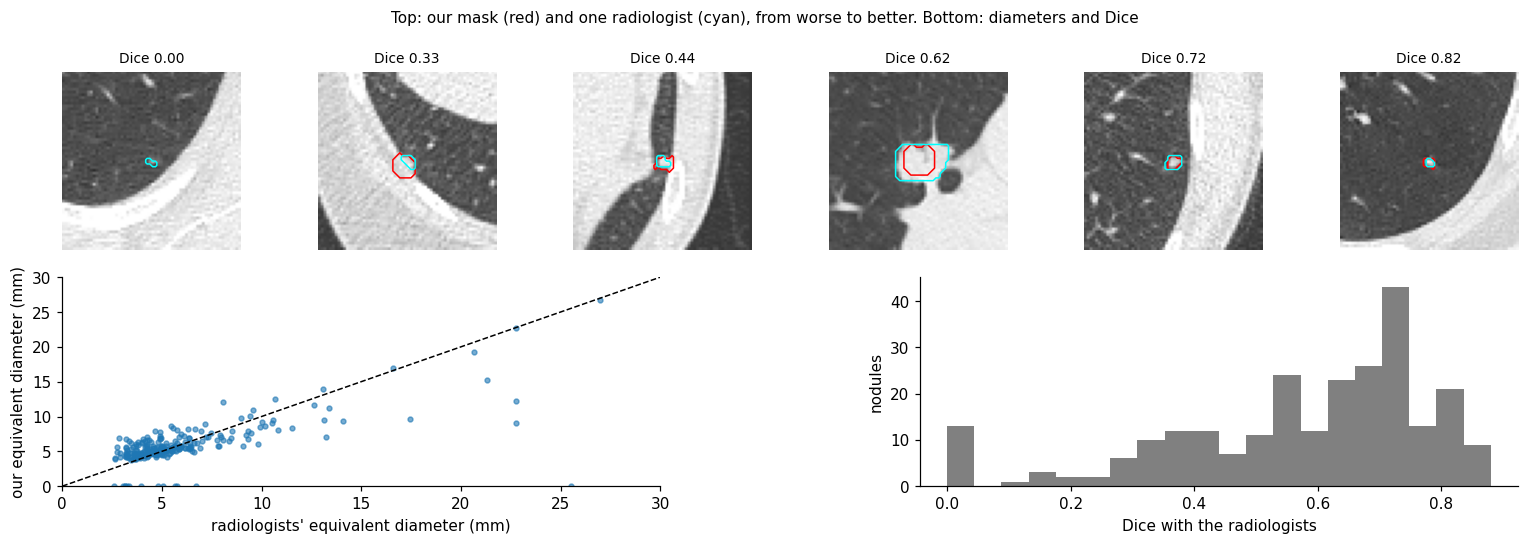

In [44]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
order = check.sort_values("dice")
picks = list(order.iloc[[10, 30, 60]].index) + list(order.iloc[[120, 180, 235]].index)
for axis, i in zip(axes[0], picks):
    p, m, q = check.patch[i], check["mask"][i], check.refs[i][0]
    axis.imshow(p[32], cmap="gray", vmin=-1350, vmax=150)
    axis.contour(m[32], levels=[.5], colors="red", linewidths=1)
    axis.contour(q[32], levels=[.5], colors="cyan", linewidths=1)
    axis.set_title(f"Dice {check.dice[i]:.2f}", fontsize=9); axis.axis("off")
axes[0, 0].set_ylabel("axial")
a = axes[1, 0]; a.remove()
ax = fig.add_subplot(2, 2, 3)
ax.scatter(check.ref_diameter, check.diameter, s=10, alpha=.6); ax.plot([0, 30], [0, 30], "k--", lw=1)
ax.set_xlabel("radiologists' equivalent diameter (mm)"); ax.set_ylabel("our equivalent diameter (mm)"); ax.set_xlim(0, 30); ax.set_ylim(0, 30)
for a in axes[1, 1:]: a.remove()
ax2 = fig.add_subplot(2, 2, 4)
ax2.hist(check.dice, bins=20, color="grey"); ax2.set_xlabel("Dice with the radiologists"); ax2.set_ylabel("nodules")
fig.suptitle("Top: our mask (red) and one radiologist (cyan), from worse to better. Bottom: diameters and Dice", fontsize=10)
plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
The two radiologists agree with each other much better than we agree with them, so our segmentation is not at their level. It is good enough to measure size on average (small bias, error around 1.5 mm) and fails mostly on nodules attached to vessels or the chest wall. We keep it because it uses nothing but the centre, so it can be applied to the test rows. A better segmentation is the most direct way to improve the features later.
</p>
<p>
One more check: the cube is 64 mm. Does any rated nodule risk being cut?
</p>
</div>

In [45]:
rated = lndb[lndb.mal_mean.notna()]
print("rated LNDb nodules:", len(rated))
print("with a radiologist diameter above 40 mm:", int((rated.diameter_mm > 40).sum()), "| above 30 mm:", int((rated.diameter_mm > 30).sum()))

rated LNDb nodules: 765
with a radiologist diameter above 40 mm: 0 | above 30 mm: 2


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    What we measure
  </h3>
<p>
For every patch we compute 21 numbers on the segmented nodule and 9 numbers in spheres around the centre. We wrote them ourselves instead of starting from the hundreds of PyRadiomics features, for three reasons: with 765 labelled nodules, hundreds of features invite overfitting; each of ours has a plain meaning that we can explain; and they are fast. Section 4 checks whether PyRadiomics adds anything.
</p>

| Group | Features | Why |
|---|---|---|
| Size | 'volume_mm3', 'diameter_mm' (of the sphere with the same volume), 'max_extent_mm' | Size is the first thing a radiologist looks at, and a diameter only baseline is strong in LIDC (Baltatzis et al., 2021) |
| Shape | 'elongation', 'flatness', 'sphericity' | Round and smooth nodules look different from spiculated or elongated ones |
| Density inside | 'hu_mean', 'hu_std', 'hu_p10', 'hu_p50', 'hu_p90', 'hu_skew' | Calcified nodules are very dense and are usually benign |
| Solid or ground glass | 'solid_fraction', 'ground_glass_fraction' | Part solid and ground glass nodules are read differently from solid ones |
| Edge | 'edge_gradient' | How sharp the border is |
| Surroundings | 'ring_mean_hu', 'ring_solid_fraction', 'contrast_hu' | A dense ring means the nodule touches a vessel or the wall |
| Segmentation | 'centre_hu', 'lung_hu', 'threshold_hu' | What the segmentation measured, which also says how confident it is |
| Spheres of 3, 5 and 8 mm | mean HU, 90th percentile, solid fraction | They need no mask, so they exist even when the segmentation fails (8% of the rated nodules), in training and test alike |

<p>
Two safeguards: every intensity feature uses the patch clipped to [-1024, 3071] HU, the range of a 12 bit CT, because some patches contain padding values down to -8192 or artefacts up to 22544 HU (the IBSI calls this re-segmentation by intensity range; Zwanenburg et al., 2020). And nodules where nothing denser than the lung is found at the centre get empty segmentation features; the model fills them with the median, but their sphere features remain.
</p>
</div>

765 rated nodules; segmented: 91.9% | features: 30
test rows with features: 2895 | segmented: 98.5%
rating
1    213
2    254
3    209
4     71
5     18


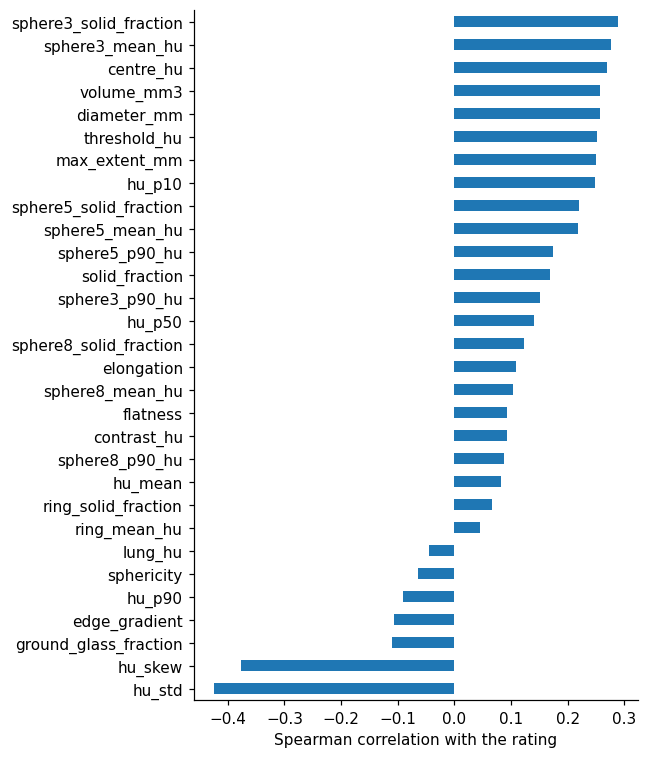

In [46]:
features = pd.read_csv(PATCHES_DIR / "features.csv")
lndb["patch_id"] = lndb.nodule_uid.str.replace(r"_(\d+)$", lambda m: f"_f{int(m.group(1)):03d}", regex=True)
data = (lndb[lndb.mal_mean.notna()].rename(columns={"diameter_mm": "diameter_mm_radiologist"}).drop(columns="volume_mm3")
        .merge(features[features.split == "train"].drop(columns="split"), on="patch_id"))
data["rating"] = np.floor(data.mal_mean + 0.5).astype(int)          # mean of the readers, rounded half up
feature_names = [c for c in features.columns if c not in ("patch_id", "split", "segmented", "error")]
print(len(data), "rated nodules; segmented:", f"{data.segmented.mean():.1%}", "| features:", len(feature_names))
print("test rows with features:", int((features.split == "test").sum()), "| segmented:", f"{features[features.split == 'test'].segmented.mean():.1%}")
print(data.rating.value_counts().sort_index().rename("nodules per class").to_string())

corr = data[feature_names + ["rating"]].corr(method="spearman")["rating"].drop("rating").sort_values()
corr.plot.barh(figsize=(6, 7)); plt.xlabel("Spearman correlation with the rating"); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
    The strongest single signals are the density inside the nodule and in the small spheres (calcified nodules are dense and benign, so the sign is negative), the surroundings and the size. We know understand that no single feature is strong, so the combination matters.
</p>

| Step | Our choice | Why |
|---|---|---|
| Resampling | 1 mm isotropic, linear interpolation, done when the patch is cut | Texture depends on voxel size (Shafiq-ul-Hassan et al., 2017); the IBSI recommends isotropic voxels |
| Intensity range | [-1024, 3071] HU | Removes padding and artefacts before discretisation |
| Discretisation | fixed bin width of 25 HU | For calibrated units such as HU the IBSI recommends a fixed bin size, so that one bin is the same density in every scan |
| Filters | original image and Laplacian of Gaussian with sigma 1, 2 and 3 mm | Edges and blobs at the scale of small nodules |
| Feature classes | first order, shape, GLCM, GLRLM, GLSZM, GLDM, NGTDM | All classes of PyRadiomics, 386 features |
| Region | the automatic mask, identical in training and test | The test file only has centres (Pedrosa et al., 2019) |

</div>

In [47]:
print("settings:", SETTINGS, "| LoG sigmas (mm):", LOG_SIGMAS_MM)
radiomics = pd.read_csv(PATCHES_DIR / "radiomics_train.csv")
icc = pd.read_csv(PATCHES_DIR / "radiomics_icc.csv")
print("regions:", radiomics.roi.value_counts().to_dict())

settings: {'binWidth': 25, 'resampledPixelSpacing': None, 'interpolator': 'sitkLinear', 'label': 1, 'minimumROIDimensions': 1, 'minimumROISize': 8, 'geometryTolerance': 0.001} | LoG sigmas (mm): [1.0, 2.0, 3.0]
regions: {'auto': 765, 'rad1': 518, 'rad2': 393, 'rad3': 119}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Are the features robust to who draws the contour?
  </h3>
<p>
A feature that changes a lot when another radiologist draws the contour measures the contour more than the nodule (Traverso et al., 2018; Zwanenburg et al., 2019). For every nodule with masks from two radiologists we compute, feature by feature, the intraclass correlation ICC(2,1): two way random effects, absolute agreement, single rater (Shrout and Fleiss, 1979). Following Koo and Li (2016), ICC of 0.75 or more is "good" and we call the feature robust.
</p>
</div>

In [48]:
summary = icc.groupby(["image", "feature_class"]).agg(features=("icc", "size"), median_icc=("icc", "median"),
                                                      robust_share=("robust", "mean")).round(2)
print(f"{icc.robust.sum()} of {len(icc)} features are robust (ICC >= 0.75); median ICC {icc.icc.median():.2f}")
summary.unstack("image")["robust_share"]

330 of 386 features are robust (ICC >= 0.75); median ICC 0.94


image,log-sigma-1-0-mm-3D,log-sigma-2-0-mm-3D,log-sigma-3-0-mm-3D,original
feature_class,,,,
firstorder,0.83,0.89,0.94,0.67
glcm,0.88,0.92,0.96,0.75
gldm,0.86,0.93,0.93,0.79
glrlm,0.88,1.00,1.00,0.75
glszm,0.94,0.81,0.75,0.81
ngtdm,0.60,0.80,0.60,0.80
shape,NaN,NaN,NaN,0.86


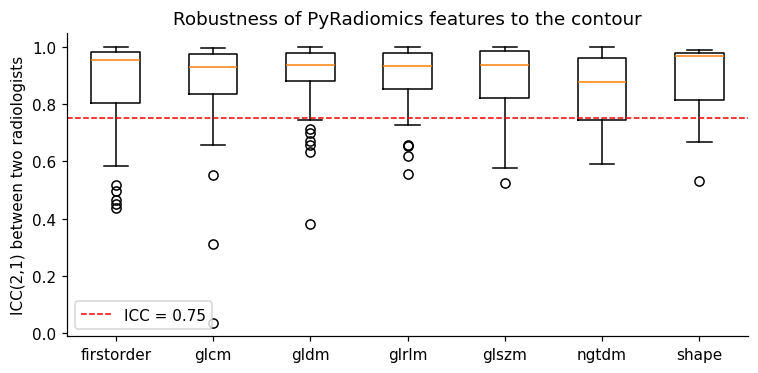

In [49]:
fig, ax = plt.subplots(figsize=(7, 3.5))
classes = sorted(icc.feature_class.unique())
ax.boxplot([icc.loc[icc.feature_class == c, "icc"].clip(lower=-0.2) for c in classes], tick_labels=classes)
ax.axhline(0.75, color="red", linestyle="--", linewidth=1, label="ICC = 0.75")
ax.set(ylabel="ICC(2,1) between two radiologists", title="Robustness of PyRadiomics features to the contour")
ax.legend(); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
Most features are robust to the difference between two radiologists' contours; NGTDM and the unfiltered texture features are the least robust. But the region we can use at test time is our automatic mask, not a radiologist's. The relevant question is therefore how well features from our mask agree with features from a radiologist's mask.
</p>
</div>

In [50]:
first_reader = (radiomics[radiomics.roi.str.startswith("rad")].dropna(subset=["original_firstorder_Mean"])
                .sort_values("roi").groupby("patch_id").head(1).set_index("patch_id"))
automatic = radiomics[radiomics.roi == "auto"].dropna(subset=["original_firstorder_Mean"]).set_index("patch_id")
common = automatic.index.intersection(first_reader.index)
icc_auto = pd.Series({f: icc_2_1(np.column_stack([automatic.loc[common, f], first_reader.loc[common, f]]))
                      for f in icc.feature})
print(f"automatic mask vs radiologist ({len(common)} nodules): median ICC {icc_auto.median():.2f}, "
      f"robust {(icc_auto >= 0.75).mean():.0%} of the features")

automatic mask vs radiologist (632 nodules): median ICC 0.73, robust 47% of the features


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Between two radiologists the median ICC is about 0.94; between our mask and a radiologist it drops to about 0.73, with fewer than half of the features robust. The weak point is our segmentation, not the features.
  </p>


  
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Do radiomics add anything to our features?
  </h3>
<p>
We compare, with the ordinal model and the same grouped cross validation, our 30 features alone against our features plus the robust radiomic features. With 300 extra features we remove redundant ones (absolute Spearman correlation above 0.9) and keep the 30 most related to the rating, both inside each training fold  and use a stronger penalty.
</p>
</div>

In [ ]:
robust = ["R_" + f for f in icc.loc[icc.robust, "feature"]]
data = data.merge(automatic[icc.feature].add_prefix("R_"), left_on="patch_id", right_index=True, how="left")
own = feature_names                     # our 21 + 9 sphere features
y, groups = data.rating.to_numpy(), data.scan_id.to_numpy()

def ordinal_pipeline(selection=(), alpha=1.0):
    return lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), *[s() for s in selection],
                                 OrdinalLogisticRegression(alpha))
comparison = {
    "our 30 features": summarise(y, groups, grouped_cv_predictions(ordinal_pipeline(), data[own], y, groups, repeats=3))["mean"],
    "our features + robust radiomics": summarise(y, groups, grouped_cv_predictions(
        ordinal_pipeline((lambda: CorrelationFilter(0.9), lambda: SelectKBest(f_regression, k=30)), alpha=10.0),
        data[own + robust], y, groups, repeats=3))["mean"]}
pd.DataFrame(comparison).T

,balanced_accuracy,macro_f1,qwk,mae,composite
our 30 features,0.377,0.406,0.501,0.633,0.651
our features + robust radiomics,0.355,0.379,0.470,0.644,0.561


In [52]:
# The same question for the size model of notebook 06_modelo: does it predict the radiologists' diameter better with radiomics?
target = size_target(data.diameter_mm_radiologist).to_numpy()
measured = data.diameter_mm_radiologist.notna().to_numpy()
for name, columns in (("our features", own), ("our features + robust radiomics", own + robust)):
    predicted = np.zeros(len(data))
    for train, test in GroupKFold(5).split(data, y, groups):
        predicted[test] = make_size_model().fit(data[columns].iloc[train], target[train]).predict(data[columns].iloc[test])
    rho = pd.Series(predicted[measured]).corr(data.diameter_mm_radiologist[measured].reset_index(drop=True), method="spearman")
    print(f"size model with {name}: Spearman {rho:.3f}")

size model with our features: Spearman 0.828
size model with our features + robust radiomics: Spearman 0.822


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The robust radiomic features do not improve the model, neither as direct inputs nor through the size model, so the final model uses our 30 features. This follows the principle of keeping the simplest model that performs as well, and it agrees with the Radiomics Quality Score, which rewards feature reduction and robustness analysis rather than the number of features (Lambin et al., 2017). The radiomic analysis stays in the report as evidence. We consider that A better segmentation would be the way to make radiomics worthwhile.
  </p>


  
</div>